# Logistics Delivery Risk Intelligence

**Author:**Niharika N K

## Objective

The objective of this analysis is to evaluate the Routewise shipments for planner intervention:

1. Forcasting hours of delay we can expect for that partcular shipment
2. Predicting wheather the product shipment has to be marked as delay risk 
3. Discovering operating patterns across the networkand which one carry most risk using clustering.

# Task 1 : Shipment data Understanding and Validation


In [210]:
import pandas as pd
import numpy as np

shipment_data_df = pd.read_csv(r"D:\Projects\Logistics Delivery Risk Intelligence\data\logistics_delivery_delay (1).csv")
print(f"Imported records count{ shipment_data_df.shape}")
print(f"Total columns count is: { shipment_data_df.shape[1]} \n and verifying its data types{shipment_data_df.info()}")

Imported records count(720, 17)
<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   shipment_timestamp          720 non-null    str    
 1   origin_hub                  720 non-null    str    
 2   destination_type            720 non-null    str    
 3   shipping_mode               720 non-null    str    
 4   carrier                     720 non-null    str    
 5   distance_km                 720 non-null    float64
 6   package_weight_kg           719 non-null    float64
 7   weather_condition           719 non-null    str    
 8   traffic_level               719 non-null    str    
 9   carrier_rating              719 non-null    float64
 10  warehouse_processing_hours  719 non-null    float64
 11  dispatch_delay_hours        720 non-null    float64
 12  handling_time_hours         720 non-null    float64
 13  expected_deliv

In [211]:
#Time coverage of the shipment data 
#Change the datatype of timestamp

shipment_data_df['shipment_timestamp'] = pd.to_datetime(shipment_data_df['shipment_timestamp'],errors= 'coerce')
print(f"To analyse, Shipment data is available from { shipment_data_df['shipment_timestamp'] .min() } to {shipment_data_df['shipment_timestamp'] .max()}")

#Distribution of every categorical column 
print("Distribution of data")
[print(f" {col} : {shipment_data_df[col].value_counts()}") 
 for col in shipment_data_df.select_dtypes(include='string').columns  
 ]


To analyse, Shipment data is available from 2026-04-01 06:00:00 to 2026-06-30 03:00:00
Distribution of data
 origin_hub : origin_hub
North Hub    180
South Hub    180
East Hub     180
West Hub     180
Name: count, dtype: int64
 destination_type : destination_type
Metro          180
Industrial     180
Rural          180
Tier-2 City    180
Name: count, dtype: int64
 shipping_mode : shipping_mode
Road    240
Rail    240
Air     240
Name: count, dtype: int64
 carrier : carrier
Carrier-A    180
Carrier-D    180
Carrier-C    180
Carrier-B    180
Name: count, dtype: int64
 weather_condition : weather_condition
Clear     180
Storm     180
Cloudy    180
Rain      179
Name: count, dtype: int64
 traffic_level : traffic_level
High      359
Low       180
Medium    180
Name: count, dtype: int64


[None, None, None, None, None, None]

#Summary statistics and Target analysis
## 1.6 Target Variable analysis 

it has two targets 
regression target : delivery delay hours

Classification target : delay required

In [212]:
print(
    f"Logistics Delivery classification target distribution:\n"
    f"{shipment_data_df['delay_required'].value_counts(normalize=True)}\n"
    f"Percentage of Logistics Delivery classification target: {(shipment_data_df['delay_required'].value_counts(normalize=True) * 100).round(2)}%\n"
   f"Regression target summary:\n{shipment_data_df['delivery_delay_hours'].describe()}"
)

Logistics Delivery classification target distribution:
delay_required
1    0.693056
0    0.306944
Name: proportion, dtype: float64
Percentage of Logistics Delivery classification target: delay_required
1    69.31
0    30.69
Name: proportion, dtype: float64%
Regression target summary:
count    720.000000
mean       4.591972
std        2.611877
min        0.000000
25%        2.397500
50%        5.125000
75%        6.632500
max       10.440000
Name: delivery_delay_hours, dtype: float64


**2. Classification target — Delay Required**

The classification target is imbalanced, with the `Delay Required` class accounting for approximately 30% of observations. This indicates that Delay-required events occur less frequently than the other class or classes. Model evaluation should therefore consider precision, recall, F1-score, and the confusion matrix rather than relying solely on accuracy.

In [213]:
## 1.4 Missing Values Analysis
# to avoid missing values affecting the model quality.

print(f"Logistics Delivery Risk DataFrame missing values:\n{shipment_data_df.isnull().sum()}")

for col in shipment_data_df.columns:
    missing_percentage = shipment_data_df[col].isnull().mean() * 100
    if missing_percentage > 0:
     print(f"Column '{col}' has {missing_percentage:.2f}% missing values.\n")
     #check the rows with missing values and its associated delay.
     print(f"\n #Only a small number of missing values were identified in : package_weight_kg  , weather_condition, traffic_level,carrier_rating and warehouse_processing_hours.")
     print(f"\nTo handle since its very few , we shall verify which sale events its triggering ")
    if shipment_data_df[col].isnull().any():
       missing_rows = shipment_data_df[shipment_data_df[col].isnull()]
       print(f"Rows with missing values in column '{col}':\n{missing_rows[['delay_required', col]]}\n")
        

Logistics Delivery Risk DataFrame missing values:
shipment_timestamp            0
origin_hub                    0
destination_type              0
shipping_mode                 0
carrier                       0
distance_km                   0
package_weight_kg             1
weather_condition             1
traffic_level                 1
carrier_rating                1
warehouse_processing_hours    1
dispatch_delay_hours          0
handling_time_hours           0
expected_delivery_hours       0
actual_delivery_hours         0
delivery_delay_hours          0
delay_required                0
dtype: int64
Column 'package_weight_kg' has 0.14% missing values.


 #Only a small number of missing values were identified in : package_weight_kg  , weather_condition, traffic_level,carrier_rating and warehouse_processing_hours.

To handle since its very few , we shall verify which sale events its triggering 
Rows with missing values in column 'package_weight_kg':
     delay_required  package_weight_kg

## 1.5 Unusual and Extreme Observations




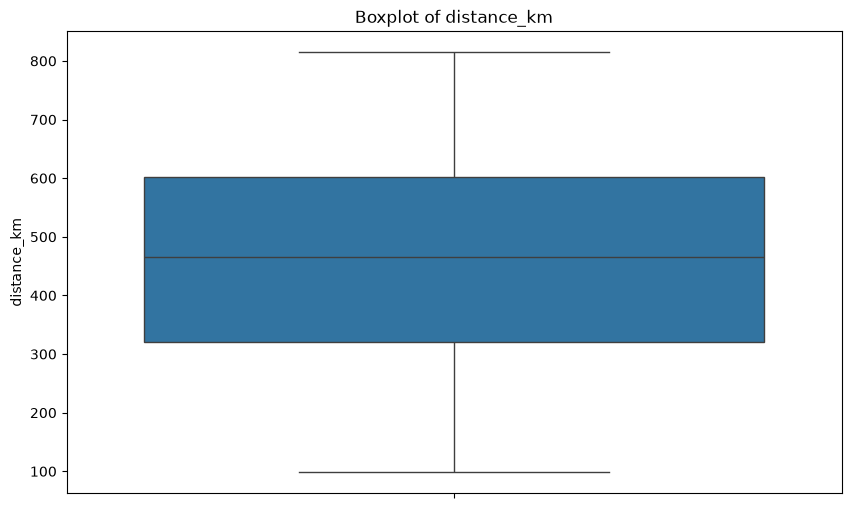

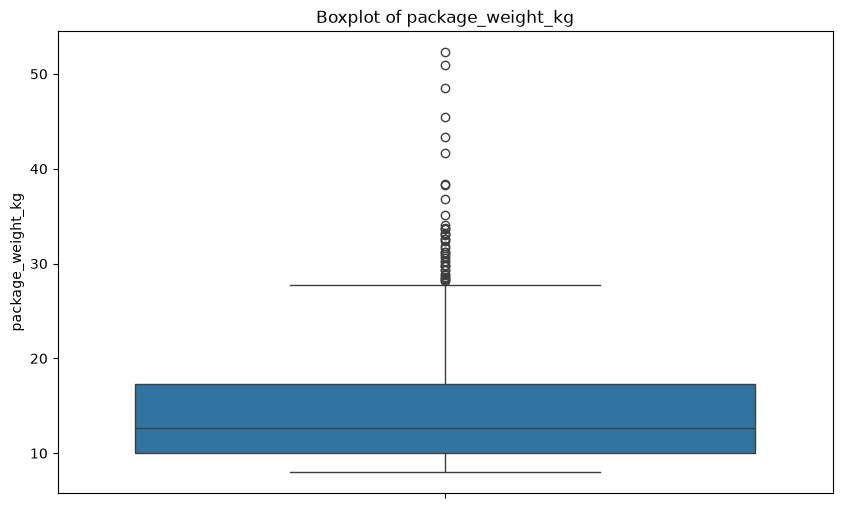

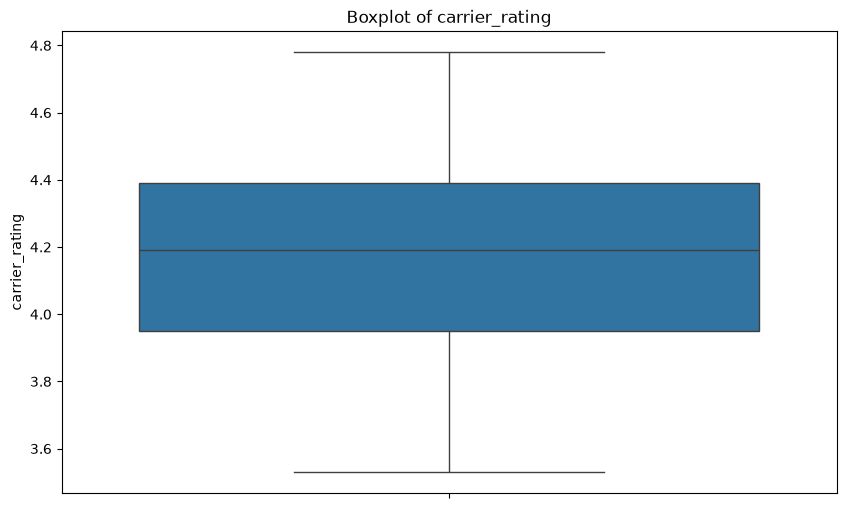

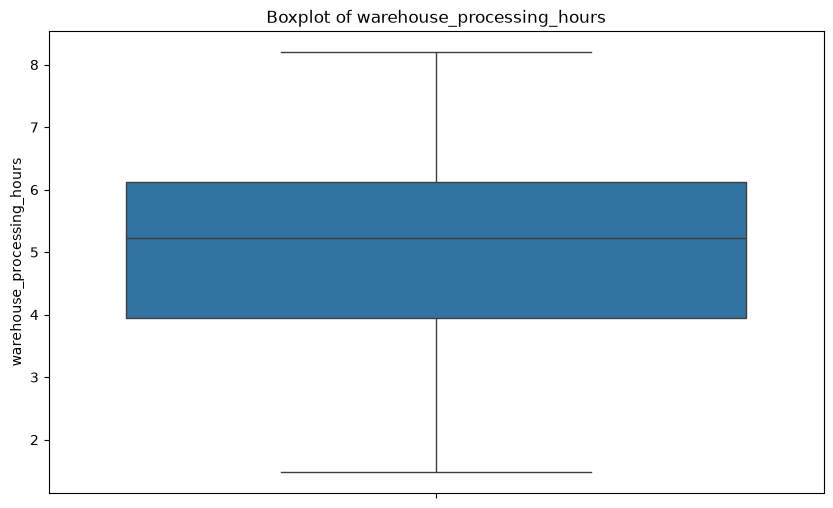

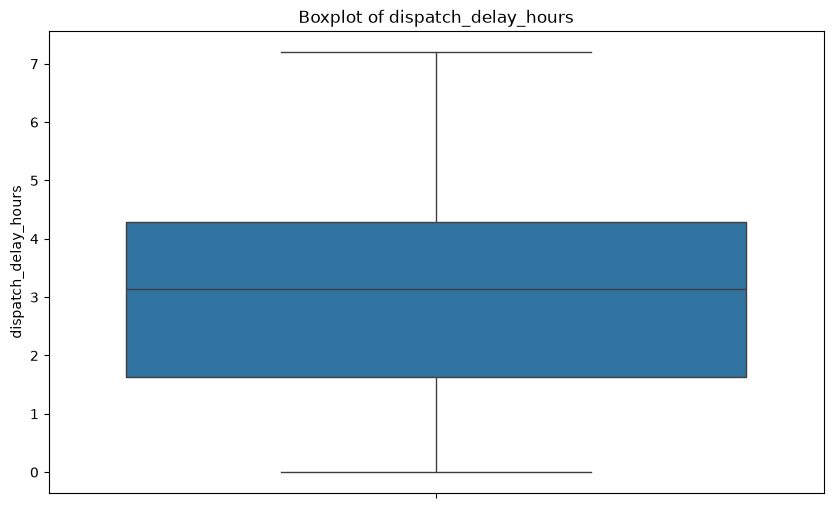

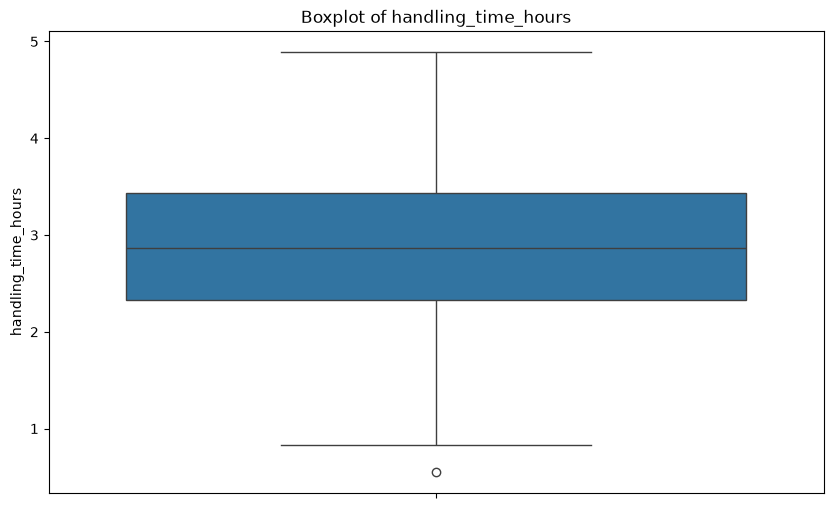

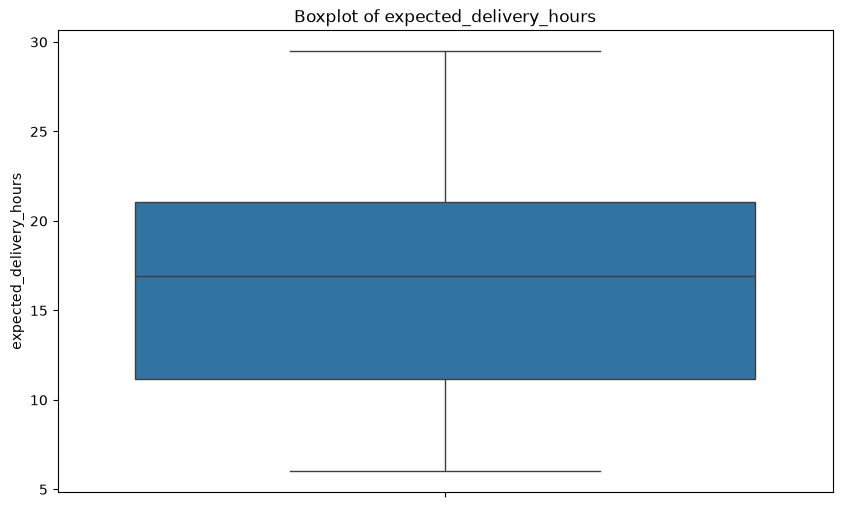

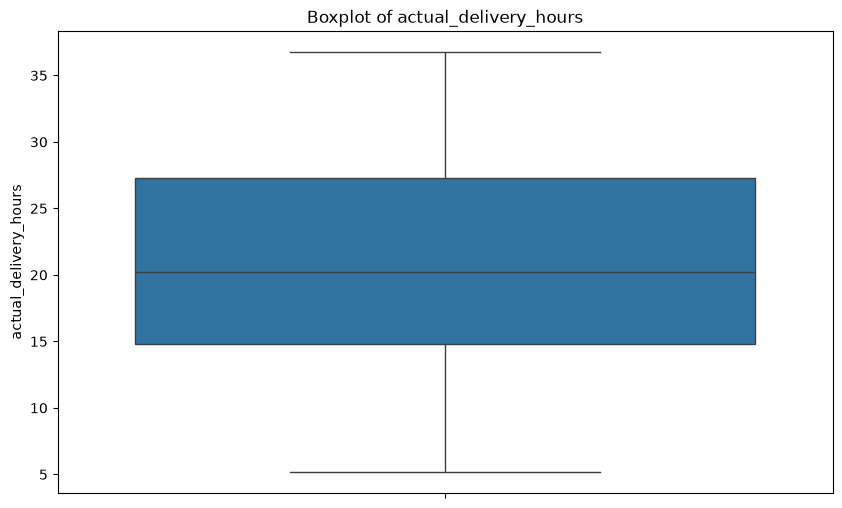

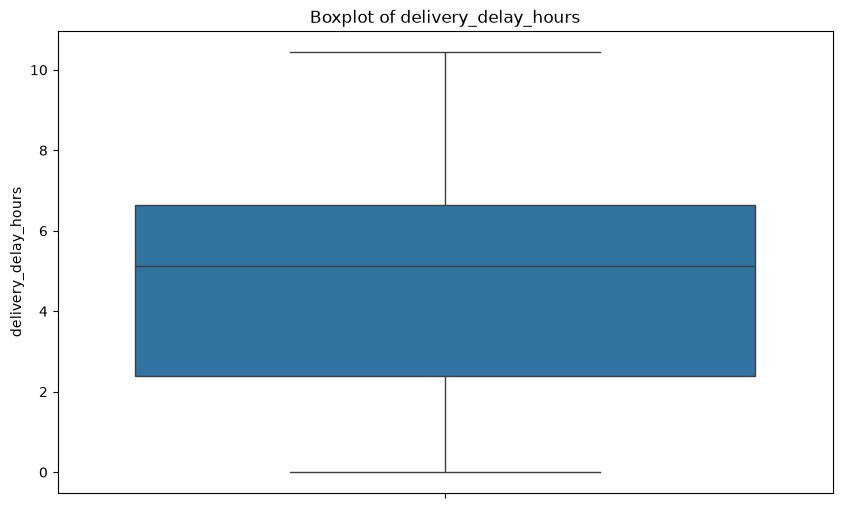

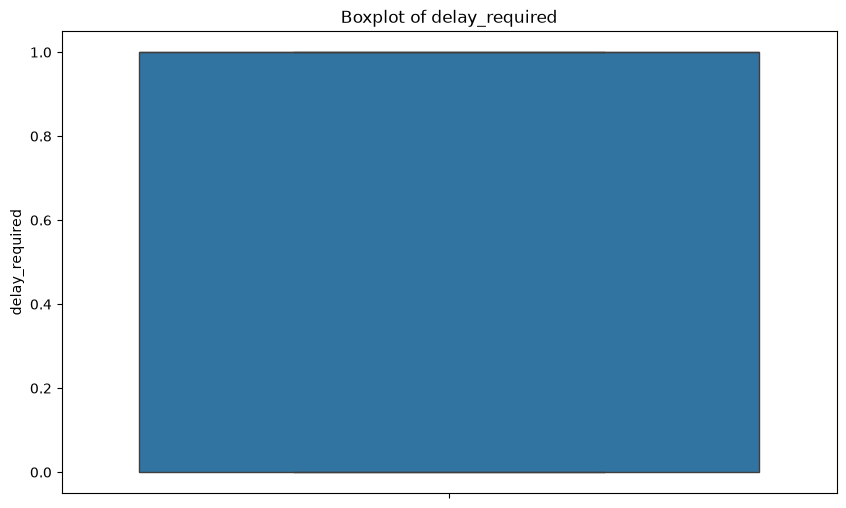

In [214]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in shipment_data_df.columns:
    if shipment_data_df[col].dtype in [np.float64, np.int64]:
        plt.figure(figsize=(10, 6))
        sns.boxplot(shipment_data_df[col])
        plt.title(f'Boxplot of {col}')
        plt.savefig(r'D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks1\boxplot_{col}.png')
        plt.show()
             

In [215]:
#Observing delay required behaviour across shipping mode, traffic level, weather condition, destination type and carrier 

categorical_col = [
    'shipping_mode',
    'traffic_level', 
    'weather_condition', 
     'destination_type',
      'carrier'

]

for col in categorical_col:
     comparision_df = shipment_data_df.groupby([col,'delay_required']).size().unstack(fill_value=0)
     print(f"\nComparison: {col} vs delay_required")
     print(f"{comparision_df}")
          


Comparison: shipping_mode vs delay_required
delay_required   0    1
shipping_mode          
Air             74  166
Rail            71  169
Road            76  164

Comparison: traffic_level vs delay_required
delay_required    0    1
traffic_level           
High             43  316
Low             177    3
Medium            1  179

Comparison: weather_condition vs delay_required
delay_required       0    1
weather_condition          
Clear              177    3
Cloudy              36  144
Rain                 7  172
Storm                1  179

Comparison: destination_type vs delay_required
delay_required      0    1
destination_type          
Industrial          1  179
Metro             177    3
Rural               7  173
Tier-2 City        36  144

Comparison: carrier vs delay_required
delay_required    0    1
carrier                 
Carrier-A       177    3
Carrier-B        36  144
Carrier-C         7  173
Carrier-D         1  179


# Task 2: Data Preparation for ML

## Purpose : Data must be transformed into a machine learning ready dataset 

In [216]:
shipment_data_df_copy = shipment_data_df.copy()

#Timestamp cpnve

shipment_data_df_copy['day_of_the_week'] = shipment_data_df_copy['shipment_timestamp'].dt.day_of_week
shipment_data_df_copy['hour_of_the_day'] = shipment_data_df_copy['shipment_timestamp'].dt.hour



# Missing values 

# Why Median to handle missing values

A distribution can look fairly symmetric overall but contain a few extreme observations.It is less sensitive to unusually large or small values.
categorical variables were imputed using the mode to preserve the existing category distribution while minimizing distortion of the dataset

In [217]:
#Missing value treatment

for col in shipment_data_df_copy.columns:
    if (shipment_data_df_copy[col].isnull().any()) and pd.api.types.is_numeric_dtype(shipment_data_df_copy[col]):
        
        print(f"Missing values before dropping {col}:\n{shipment_data_df_copy[col].isnull().sum()}")
        
        shipment_data_df_copy[col] = shipment_data_df_copy[col].fillna(shipment_data_df_copy[col].median())

        print(f"Missing values after filling {col}:\n{shipment_data_df_copy[col].isnull().sum()}")
    elif (shipment_data_df_copy[col].isna().any()) and pd.api.types.is_string_dtype(shipment_data_df_copy[col]):
        print(f"Missing values before dropping {col}:\n{shipment_data_df_copy[col].isna().sum()}")
        
        shipment_data_df_copy[col] = shipment_data_df_copy[col].fillna(shipment_data_df_copy[col].mode()[0])

        print(f"Missing values after filling {col}:\n{shipment_data_df_copy[col].isna().sum()}")
        

Missing values before dropping package_weight_kg:
1
Missing values after filling package_weight_kg:
0
Missing values before dropping weather_condition:
1
Missing values after filling weather_condition:
0
Missing values before dropping traffic_level:
1
Missing values after filling traffic_level:
0
Missing values before dropping carrier_rating:
1
Missing values after filling carrier_rating:
0
Missing values before dropping warehouse_processing_hours:
1
Missing values after filling warehouse_processing_hours:
0


# Encode categories 

## Using One-Hot for 'origin_hub','destination_type','shipping_mode','carrier','weather_condition'

## Using Ordinal for Traffic Level

Ordinal encoding was chosen for traffic_level because its categories (Low, Medium, High) have a natural order representing increasing traffic severity. Unlike one-hot encoding, it preserves this ordinal relationship while keeping the number of features unchanged, making it a suitable choice for this feature.

In [218]:
# One Hot encoding 

categorical_encode_one_hot = ['origin_hub','destination_type','shipping_mode','carrier','weather_condition']
shipment_data_encoded = pd.get_dummies(shipment_data_df_copy,columns=categorical_encode_one_hot,drop_first=True)
encoded_col = []
for original_col in categorical_encode_one_hot :
    for col in shipment_data_encoded.columns:
        if col.startswith(f"{original_col}_"):  
           encoded_col.append(col)

for col in encoded_col:
   print(f"Encoded columns for '{col}'")
   print(f"{shipment_data_encoded[col].head(5)}")


   

Encoded columns for 'origin_hub_North Hub'
0     True
1    False
2    False
3    False
4     True
Name: origin_hub_North Hub, dtype: bool
Encoded columns for 'origin_hub_South Hub'
0    False
1     True
2    False
3    False
4    False
Name: origin_hub_South Hub, dtype: bool
Encoded columns for 'origin_hub_West Hub'
0    False
1    False
2    False
3     True
4    False
Name: origin_hub_West Hub, dtype: bool
Encoded columns for 'destination_type_Metro'
0     True
1    False
2    False
3    False
4     True
Name: destination_type_Metro, dtype: bool
Encoded columns for 'destination_type_Rural'
0    False
1    False
2     True
3    False
4    False
Name: destination_type_Rural, dtype: bool
Encoded columns for 'destination_type_Tier-2 City'
0    False
1    False
2    False
3     True
4    False
Name: destination_type_Tier-2 City, dtype: bool
Encoded columns for 'shipping_mode_Rail'
0    False
1     True
2    False
3    False
4     True
Name: shipping_mode_Rail, dtype: bool
Encoded columns 

In [219]:
# Ordinal Encoding

from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(
    categories= [['Low','Medium','High']]
)

shipment_data_df_copy['traffic_level_encoded'] = encoder.fit_transform(shipment_data_df_copy[['traffic_level']] ).ravel()


#Scaling will be done while training LR model

# Inspect Outliers

In [220]:
outlier_summary = [  ]
for col in shipment_data_df_copy.columns:
    if pd.api.types.is_numeric_dtype(shipment_data_df_copy[col]):
     Q1 = shipment_data_df_copy[col].quantile(0.25)
     Q3 = shipment_data_df_copy[col].quantile(0.75)

     IQR = Q3 - Q1

     lower_bound = Q1 - 1.5 * IQR
     upper_bound = Q3 + 1.5 * IQR

     outliers = shipment_data_df_copy[
                     (shipment_data_df_copy[col]< lower_bound)|
                     (shipment_data_df_copy[col]> upper_bound)

     ].shape[0]
     max = shipment_data_df_copy[col].max()
     outlier_summary.append((Q1,Q3,IQR,col,outliers,max))

     pd.DataFrame(
        outlier_summary,columns=['Q1','Q3','IQR','col','outlier_count','max']
     )
print(f"Outlier summary:\n{pd.DataFrame(outlier_summary, columns=['Q1', 'Q3', 'IQR', 'col', 'outlier_count','max'])}")


Outlier summary:
          Q1        Q3       IQR                         col  outlier_count  \
0   320.4250  602.6750  282.2500                 distance_km              0   
1    10.0000   17.2250    7.2250           package_weight_kg             41   
2     3.9500    4.3900    0.4400              carrier_rating              0   
3     3.9400    6.1300    2.1900  warehouse_processing_hours              0   
4     1.6275    4.2800    2.6525        dispatch_delay_hours              0   
5     2.3300    3.4325    1.1025         handling_time_hours              1   
6    11.1600   21.0575    9.8975     expected_delivery_hours              0   
7    14.8175   27.2625   12.4450       actual_delivery_hours              0   
8     2.3975    6.6325    4.2350        delivery_delay_hours              0   
9     0.0000    1.0000    1.0000              delay_required              0   
10    1.0000    5.0000    4.0000             day_of_the_week              0   
11    5.2500   15.7500   10.5000   

### Outlier Detection Using the IQR Method — Observations

The Interquartile Range (IQR) method was used to identify potential outliers in the numerical features of the Logistics Delivery Risk dataset.

- **Package weight:** `package_weight_kg` contains 41 potential outliers, with Q1 = 10.00 kg, Q3 = 17.225 kg, and IQR = 7.225 kg. The maximum observed weight is 52.30 kg, indicating that some shipments have considerably higher weights than the central 50% of the data.
- **Handling time:** `handling_time_hours` contains only one potential outlier, suggesting that extreme values are uncommon in this feature.
- **Other numerical features:** No outliers were detected in the remaining features using the IQR method.

**Conclusion and action:** Package weight requires further investigation to determine whether the extreme values represent valid heavy shipments or data-entry errors. These observations should not be removed automatically, as high-weight shipments may reflect genuine operational conditions. The single handling-time outlier should also be reviewed. Any treatment, such as correction, capping, or retention, should be based on domain knowledge and its potential impact on model performance.

In [221]:
#target columns are seperated
y_reg = shipment_data_df_copy['delivery_delay_hours']
y_cls = shipment_data_df_copy['delay_required']

X = shipment_data_df_copy.drop(columns=['delivery_delay_hours','delay_required'])


# Task 3: Feature Engineering and Selection 

Feature engineering was guided by the operational requirement to identify at-risk shipments early enough for intervention. Route intensity was derived from distance and expected delivery time to represent planned delivery demand. Predictor eligibility was assessed based on information available at the intended prediction point. Target and post-outcome fields were excluded to prevent data leakage, while feature selection was used to assess the relevance and redundancy of the remaining predictors.

Verifying new features
count    720.000000
mean      30.327589
std       14.289778
min        8.327703
25%       20.964836
50%       25.972550
75%       33.754380
max       81.104218
Name: route_intensity, dtype: float64
                     mean     median
delay_required                      
0               22.294395  19.923810
1               33.885377  27.027892


<Axes: xlabel='delay_required', ylabel='route_intensity'>

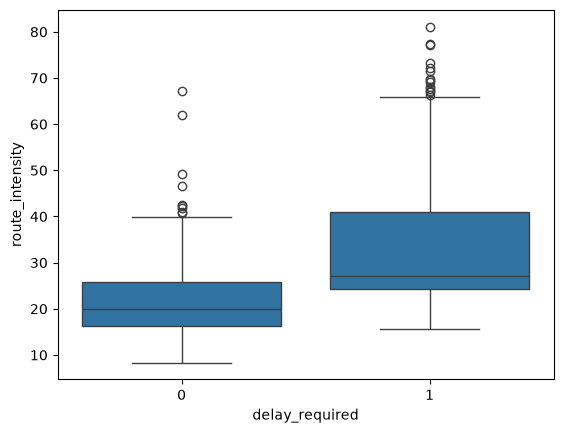

In [222]:
#Route Intensity

shipment_data_df_copy['route_intensity'] = (
    shipment_data_df_copy['distance_km']
    / shipment_data_df_copy['expected_delivery_hours']
)
print(f"Verifying new features")
print(f"{shipment_data_df_copy['route_intensity'].describe()}")

print(f"{shipment_data_df_copy.groupby('delay_required')['route_intensity'].agg(['mean','median'])}")

sns.boxplot(
    data= shipment_data_df_copy,
    x = 'delay_required',
    y = 'route_intensity'
  )

# Correlation Analysis 

To understand relationships between shipment metrics and target variable 
To determine which features may provide predictive value during model developement


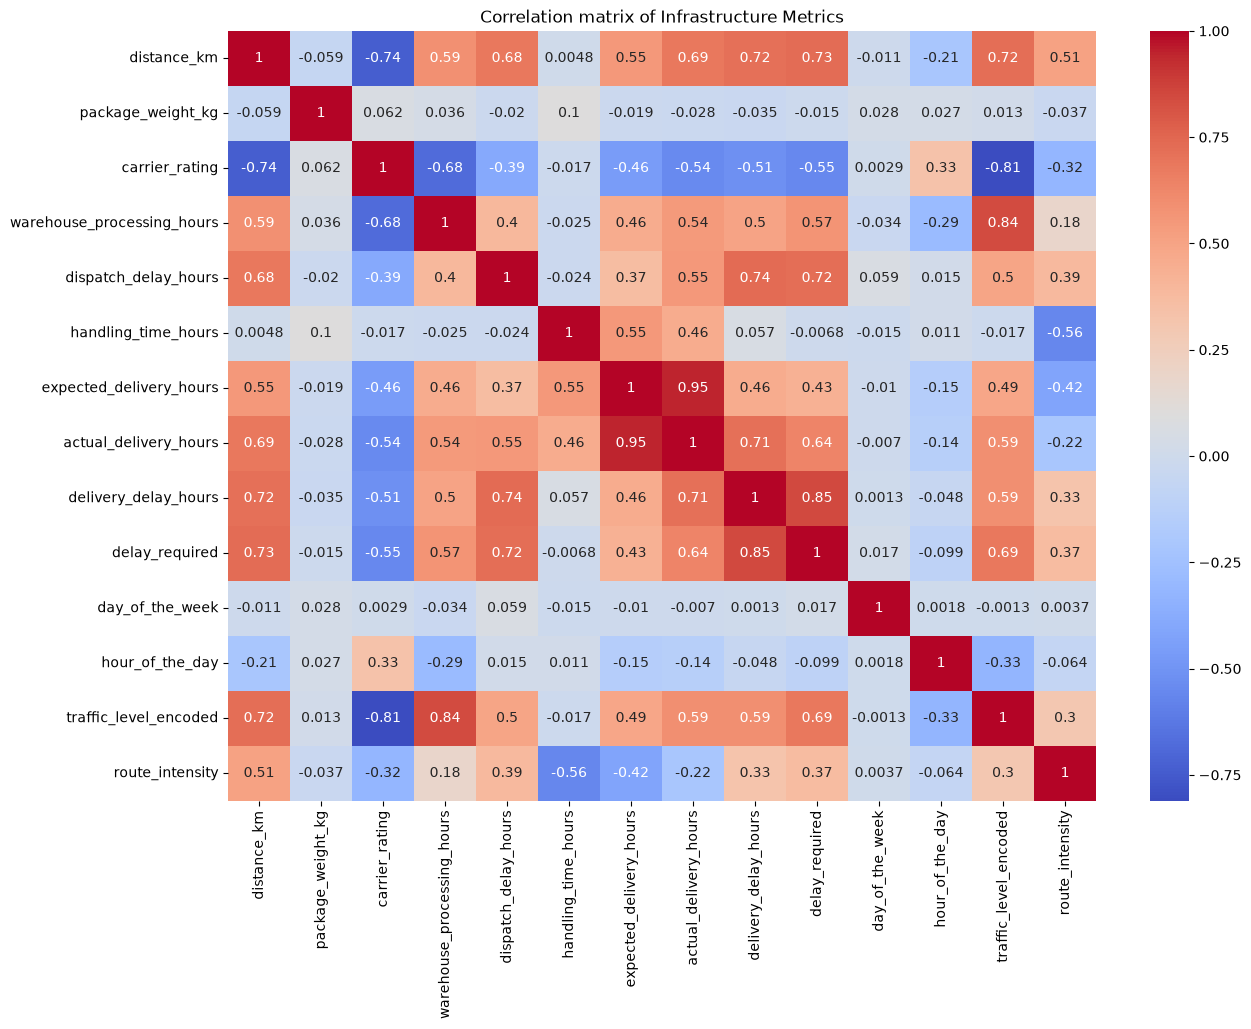

In [223]:
corre_matrix = (
    shipment_data_df_copy.select_dtypes(include='number').corr()
     )

plt.figure(figsize=(14,10))

sns.heatmap(
    data = corre_matrix,
    cmap="coolwarm",
    annot= True,
    fmt=".2g"
)

plt.title(
    "Correlation matrix of Infrastructure Metrics")

plt.savefig(
   r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks3\correlation_heatmap.png"

)

plt.show()

## Correlation Analysis and Feature Selection

A correlation matrix was generated to examine the linear relationships between numerical features and identify potential redundancy among predictors.

### Key Observations

**1. Features associated with delivery delay**

- `distance_km` has a positive correlation of approximately **0.73** with `delay_required`, indicating that longer-distance shipments tend to be associated with a higher delay rate in this dataset.
- `dispatch_delay_hours` has a correlation of approximately **0.72** with `delay_required`, while `warehouse_processing_hours` has a correlation of approximately **0.57**.
- `carrier_rating` has a negative correlation of approximately **−0.55** with `delay_required`, suggesting that higher carrier ratings are associated with a lower delay rate.
- The engineered feature `route_intensity` has a positive correlation of approximately **0.37** with `delay_required`. This indicates a potential relationship with delivery risk, although its additional predictive value must be validated.

These correlations indicate associations rather than causation and do not, by themselves, establish which features will perform best in a predictive model.

**2. Potentially redundant features**

- `expected_delivery_hours` and `actual_delivery_hours` have a strong positive correlation of approximately **0.95**.
- `warehouse_processing_hours` and `traffic_level_encoded` have a correlation of approximately **0.84**.
- `carrier_rating` and `traffic_level_encoded` have a negative correlation of approximately **−0.81**.
- `distance_km` and `traffic_level_encoded` have a positive correlation of approximately **0.72**.

These relationships warrant further investigation. Highly correlated predictors may contain overlapping information, particularly for models sensitive to multicollinearity. However, correlated features should not automatically be removed because each may still provide useful predictive information.

**3. Features with weak linear relationships**

`package_weight_kg`, `day_of_the_week`, and `hour_of_the_day` show correlations close to zero with `delay_required`. This indicates little linear association with the target in the current dataset. However, these features may still capture nonlinear relationships or patterns that are useful to a predictive model, so their usefulness should be assessed through model-based feature selection and validation.

### Feature Selection Decisions

Correlation analysis was used as an initial screening step rather than the sole basis for feature elimination. Features were also assessed for business relevance, availability at the intended prediction time, potential redundancy, and risk of data leakage.

Post-outcome variables such as `actual_delivery_hours` and `delivery_delay_hours` were excluded from the early-warning predictor set because they reveal information about the completed delivery outcome. The target variable `delay_required` was retained only as the classification target and excluded from the predictors.

The remaining eligible features, including `distance_km`, `carrier_rating`, `expected_delivery_hours`, `traffic_level_encoded`, and the engineered `route_intensity`, will be evaluated using an appropriate feature-selection method and model validation. Final retention or removal decisions will be based on predictive performance and operational relevance rather than correlation values alone.

In [224]:
target = 'delivery_delay_hours'

candidate_features = [
    'distance_km',
    'package_weight_kg',
    'carrier_rating',
    'expected_delivery_hours',
    'traffic_level_encoded',
    'day_of_the_week',
    'hour_of_the_day',
    'route_intensity'
]

x = shipment_data_df_copy[candidate_features]
y = shipment_data_df_copy[target]

# Task 4 : Demand Forecasting (Regression)

## Buisness Objective 

Planner team need early visibility into delay hours so they can re route or expidiate decisions can be made proactively rather than reactively.

The objective of this task is to predict the expected delay hours for the shipment in network using current infrastructure and workload telemetry.

Target variable :

- Linear Regression 
- Random Forest Regressor 

Eval Metrics :

- MAE
- RMSE

In [225]:
#chronological split

split_index = int(len(x)*0.8)

X_train = x[:split_index]
X_test = x[split_index:]
Y_train = y[:split_index]
Y_test = y[split_index:]

In [226]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train,Y_train)

lr_pred = lr.predict(X_train)
lr_pred.shape


(576,)

In [227]:
from sklearn.metrics import mean_squared_error,mean_absolute_error

# Use the regression target and the matching chronological split
Y_train = y.iloc[:split_index]
Y_test = y.iloc[split_index:]

lr.fit(X_train, Y_train)
lr_pred = lr.predict(X_test)

mae = mean_absolute_error(Y_test, lr_pred)
rmse = np.sqrt(mean_squared_error(Y_test, lr_pred))

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")


MAE: 1.3273168749974387
RMSE: 1.6797680417312468


In [228]:
results = pd.DataFrame()

results['Actual'] = Y_test
results['Prediction'] = lr_pred
results['Error'] = abs(lr_pred-Y_test)
results['Delay_required'] = (
    shipment_data_df.iloc[split_index:]
    ['delay_required'].values
)

results.groupby(
    'Delay_required'
)['Error'].mean()


Delay_required
0    1.243730
1    1.362904
Name: Error, dtype: float64

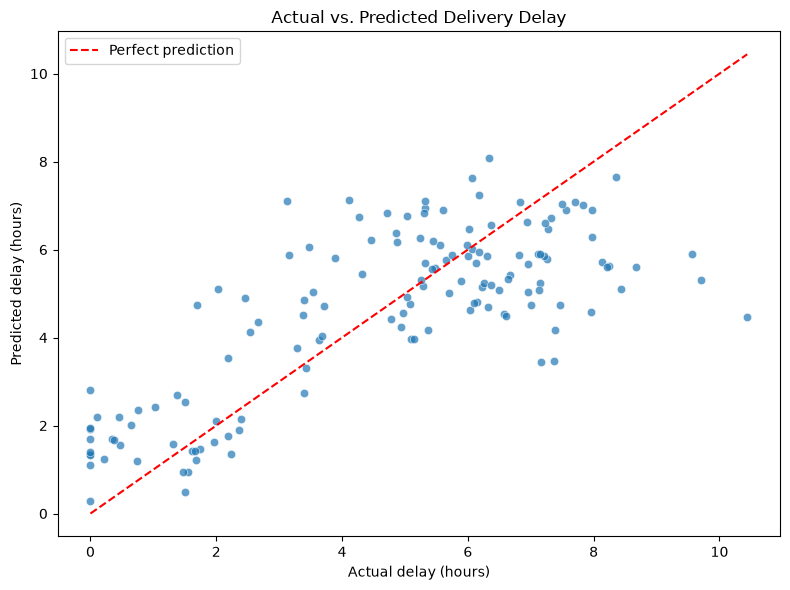

<Figure size 640x480 with 0 Axes>

In [229]:
# Actual vs. predicted delivery delay hours on the test set
plt.figure(figsize=(8, 6))
sns.scatterplot(data=results, x='Actual', y='Prediction', alpha=0.7)

# Perfect predictions fall on this reference line
plot_min = min(results['Actual'].min(), results['Prediction'].min())
plot_max = results[['Actual', 'Prediction']].to_numpy().max()
plt.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect prediction')

plt.xlabel('Actual delay (hours)')
plt.ylabel('Predicted delay (hours)')
plt.title('Actual vs. Predicted Delivery Delay')
plt.legend()
plt.tight_layout()
plt.show()

plt.savefig(r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks4\actual_vs_predicted_delay_visualization.png")

### Regression Results: Actual vs. Predicted Delay

On the test set, the Linear Regression model achieved an **MAE of 1.33 hours** and an **RMSE of 1.68 hours**. Predictions are off by about 1.33 hours on average; the higher RMSE indicates that some larger errors have a greater impact.
However, the model tends to overpredict low delays and underpredict high delays, indicating weaker performance for extreme shipment conditions

The model should therefore be treated as baseline decision-support model. Its operational suitability depends on whether an error of approximatly 1 hour 
20 min falls within the buisness's acceptable planning tolerance and wheather it meaningfully outperforms a simple baseline

# Task 5

Predict whether Delay Required Flag (Classification)

## Buisness objective

The goal is to predict wheather planner intervention is needed while delay is flagged

Target variable 

- scale_up_required

Models Evaluated

- Decision Tree Classifier
- Random Forest Classifeir

Evaluation metrics 

-Accuracy
-Precision
-Recall
- F1 score 
- Confusion matrix



In [230]:
target = 'delay_required'


x = shipment_data_df_copy.drop(columns=['delay_required','delivery_delay_hours','actual_delivery_hours','shipment_timestamp','weather_condition','traffic_level','origin_hub','destination_type','shipping_mode','carrier'])
y = shipment_data_df_copy[target]

In [231]:
X_train = x[:split_index]
X_test = x[split_index:]
Y_train = y[:split_index]
Y_test = y[split_index:]

In [232]:
from sklearn.tree import DecisionTreeClassifier

dt_cls = DecisionTreeClassifier(
    random_state=42
) 

dt_cls.fit(X_train,Y_train)

dt_pred = dt_cls.predict(X_test)


In [233]:
from sklearn.ensemble import RandomForestClassifier

rf_cls =  RandomForestClassifier(
    n_estimators= 100,
    random_state=42
)

rf_cls.fit(X_train,Y_train)

rf_pred = rf_cls.predict(X_test)



In [234]:
from sklearn.metrics import(

accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix

)

In [235]:
def evaluate(
    test,pred,model    
):

    print(f"\n {model}")

    print(
        f"Accuracy:{accuracy_score(test,pred)}"
    )
    print(
            f"Precision:{precision_score(test,pred)}"
        )
    print(
            f"Recall:{recall_score(test,pred)}"
        )
    print(
        f"F1 Score:{f1_score(test,pred)}"
    )
    

In [236]:
evaluate(Y_test, rf_pred, "Random Forest Classifier")
evaluate(Y_test, dt_pred, "Decision Trees")


 Random Forest Classifier
Accuracy:0.9513888888888888
Precision:0.9351851851851852
Recall:1.0
F1 Score:0.9665071770334929

 Decision Trees
Accuracy:0.8819444444444444
Precision:0.9285714285714286
Recall:0.900990099009901
F1 Score:0.914572864321608


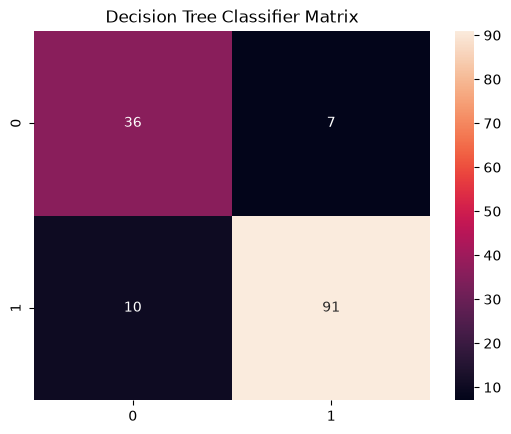

In [237]:
cm_dt = confusion_matrix(
    Y_test,dt_pred
)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d'
)

plt.title(
    "Decision Tree Classifier Matrix"
)
plt.savefig(r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks5\Confusion_matrix_DT.png")
plt.show()

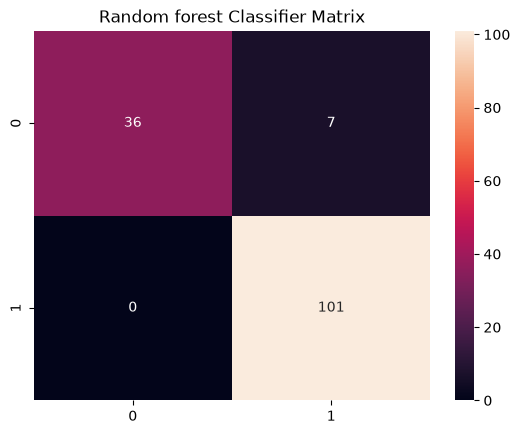

In [238]:
cm_rf = confusion_matrix(
    Y_test,rf_pred
)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d'
)

plt.title(
    "Random forest Classifier Matrix"
)
plt.savefig(r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks5\Confusion_matrix_RF.png")
plt.show()

### Precision and Recall: Operational Impact

Precision measures how often a shipment flagged as delay-risk actually requires intervention. Lower precision creates false alarms, resulting in unnecessary planner effort on shipments that would otherwise arrive normally 

Recall measures how many actual delay-risk shipments are successfully identified. Lower recall results in missed delay-risk shipments , which may reach the customer late without any proactive intervention.

For this logistics use case, Recall is particularly important because the cost of missing a genuinely delayed shipment is likely to be greater than reviewing an additional false alarm.

### Model Comparison and Selection

Random Forest demonstrated better performance than Decision Tree across all evaluation metrics.

It achived an accuracy of 95.14%,precision of 93.52%, recall of 100%, and F1 score of 96.65%.

The most important improvement is Recall, Random Forest achived 100% Recall, meaning that all delay-risk shipments in the evaluation period were successfully identified.

Although a small number of false positives alerts may still occur, this is preferable for RouteWise's planning workflow because planner review carries less operational impact than missing a shipment that ultimately reaches the customer late.

Therefore, Random Forest is selected as the more useful model for positive shipment delay-risk identification.

# Task 6 : Discover Shipment Operating Patterns using Clustering 

## Objective 

The Objective is to identify recurring shipment operating patterns using on;y information available before the delivery outcome is known

K-Means clustering is used to group shipments with similar operational characteristics without using delivery outcomes or target variables 

In [239]:
candidate_features = [
    'distance_km',
    'package_weight_kg',
    'carrier_rating',
    'expected_delivery_hours',
    'traffic_level_encoded',
    'day_of_the_week',
    'hour_of_the_day',
]

x = shipment_data_df_copy[candidate_features]

cluster_x = scaler.fit_transform(
    x
)

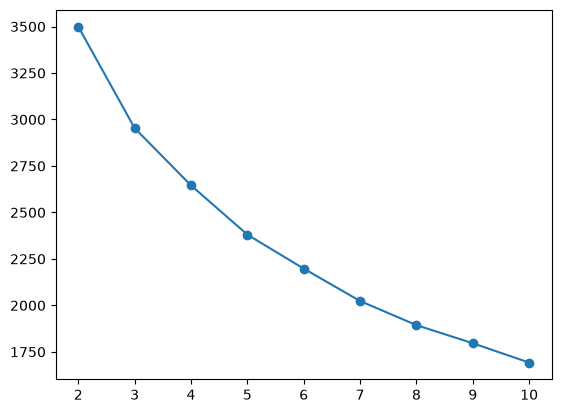

In [240]:
from sklearn.cluster import KMeans

inertia = []
for k in range(2,11):
    Kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    Kmeans.fit(cluster_x)
    inertia.append(Kmeans.inertia_)

plt.plot(
range(2,11),
inertia,
marker = 'o'
         )
plt.show
plt.savefig(r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks6\elbow_curve.png")


In [241]:
from sklearn.metrics import silhouette_score

scores = [ ]

for k in range(2,11):
    labels = KMeans(
       random_state=42,
       n_clusters = k,
       n_init = 10
    )

    labels = labels.fit_predict(
        cluster_x
    )
    scores.append(
        silhouette_score(
            cluster_x,
            labels
        )
    )

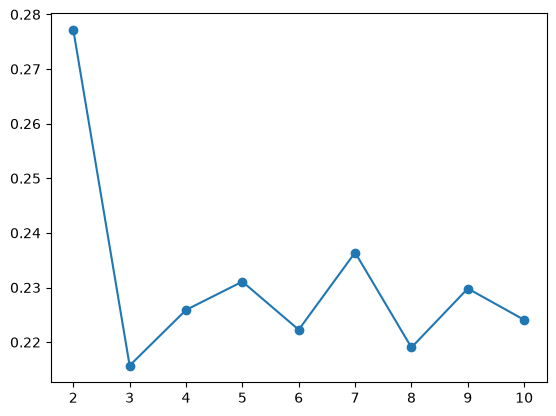

In [242]:
plt.plot(
    range(2,11),
    scores,
    marker = 'o'
         )
plt.show
plt.savefig(r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks6\silhouette_curve.png")

In [243]:
clusters = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
cluster_labels = clusters.fit_predict(cluster_x)




In [244]:
df_cluster = shipment_data_df_copy[candidate_features].copy()
df_cluster['clusters'] = cluster_labels

In [245]:
cluster_summary = (
    df_cluster.groupby('clusters')
    .mean()
    .round(2)
)

cluster_summary.T

clusters,0,1
distance_km,301.81,544.51
package_weight_kg,14.87,14.67
carrier_rating,4.44,4.03
expected_delivery_hours,11.42,18.98
traffic_level_encoded,0.30,1.77
day_of_the_week,3.09,2.98
hour_of_the_day,13.42,8.91


Elbow:
Useful improvement up to around 2-3 clusters

Silhoutte:
k=2 has highest score

Buisness :
Two clusters produced understandable shipment operating patterns


### Cluster Interpretation

**Cluster 0 : Lower-Complexity Shipments**

Cluster 0 contains shorter-distance shipments with lower traffic levels, higher carrier ratings, and shorter expected delivery times. These characteristics indicate relatively favorable shipment operating conditions 

**Cluster 1: Higher-Complexity Long-Haul Shipments**

Cluster 1 contains longer-distance shipments operating under higher traffic levels, with comparatively lower carrier ratings and longer expected delivery times. These characteristics indicate greater operational complexity.

Package weight and day of the week remain similar across both clusters and therefore do not appear to be major drivers of the segmentation.


### Operational Attention

Cluster 1 deserves closer operational attension attension because it combines longer shipment distances, heavier traffic conditions, lower carrier ratings, and longer expected delivery windows.

these pre-outcome characteristics indicate increased operational complexity and greater exposure to disruption, RouteWise planners could prioritize shipments in this cluster for earlier review, closer monitoring or proactive coordination with carriers.

Cluster 0 appears to require comparatively less attension because it operates under shorter-distance, lower-traffic, and higher-rated carrier conditions.

### Selection of K

Candidate cluster counts from K=2 to K=10 were evaluated using the Elbow Method and Silhoutte Score.

The Elbow curve shows substantial improvement at the lower values of K, followed by progressively smaller reductions in inertia as additional clusters are introduced.

The Silhoutte Score reaches its highest value at K=2, indicating that the two-cluster solution provides the strongest seperation among the evaluated candidates.

The resulting clusters also produce clear and understanding shipment operating patterns:lower-complexity long-haul shipments 

Therefore, K=2 was selected based on statistical seperation, model simplicity and operational interpretability 

The Silhoutte Score is approximately 0.28, indicating that the clusters still overalp to some extent. They should therefore be treated as broad operational patterns rather than completely separate shipment categories.

# Task 7 : Reduce Dimensions and Visualize Results

In [246]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components= 2,

)

pca_result = pca.fit_transform(
    cluster_x
)

In [247]:
df_pca = pd.DataFrame(
    pca_result,
    columns=[
        'PC1',
        'PC2'
    ]
)

df_pca['cluster'] = df_cluster['clusters']

In [248]:
retained_info= pca.explained_variance_ratio_.sum()

print(f"The first two Principal components retained {(retained_info*100)} % of the total variance,Some seperation may exist in the remaining 41.9% that isn't visible in the 2D plot")


The first two Principal components retained 58.127771458817115 % of the total variance,Some seperation may exist in the remaining 41.9% that isn't visible in the 2D plot


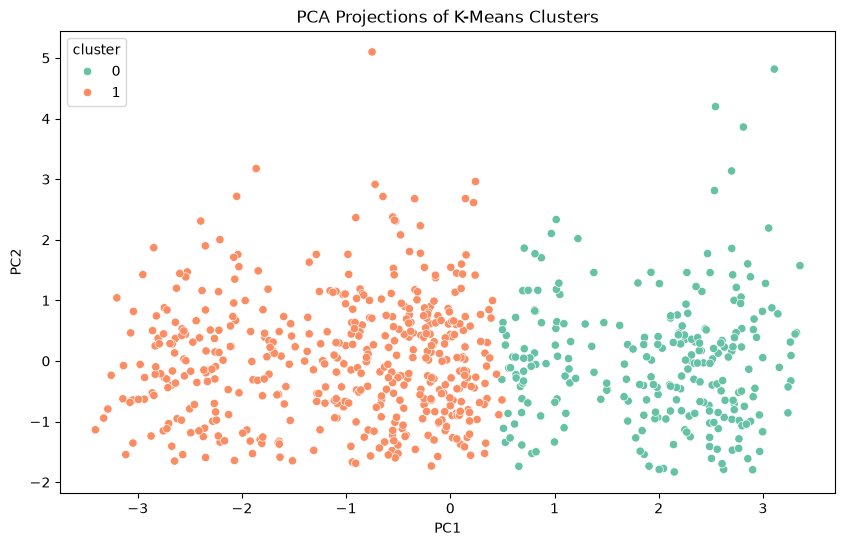

In [249]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data = df_pca,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette = 'Set2'
)

plt.title(
    "PCA Projections of K-Means Clusters"
)

plt.savefig(r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks7\pca_clusters.png",bbox_inches='tight')

plt.show()

#Delay Behaviour by Operational Category

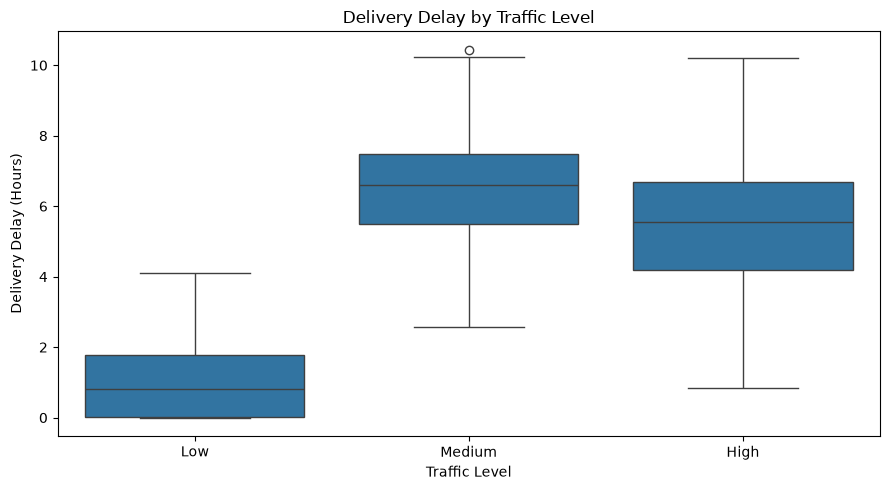

In [250]:
plt.figure(figsize=(9,5))
sns.boxplot(
    data=shipment_data_df_copy,
    x='traffic_level',
    y='delivery_delay_hours'
)

plt.title("Delivery Delay by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Delivery Delay (Hours)")

plt.tight_layout()
plt.savefig(r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks7\delivery_delay_by_traffic.png")
plt.show()


### Observation

Low-Traffic shipments show significantly lower delivery delays.

Medium and high traffic conditions have higher ans more variable delays , although their distribution overlap considerably.

This indicates that traffic level is an important delivery-risk factir, but should be consideed alongside other operational features



In [251]:
feature_importance = pd.DataFrame(
    {
        'Feature': X_train.columns,
        'Importance': rf_cls.feature_importances_
    }
)

feature_importances = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importances.head(10)

,Feature,Importance
9,traffic_level_encoded,0.262935
0,distance_km,0.219424
4,dispatch_delay_hours,0.149073
2,carrier_rating,0.083813
3,warehouse_processing_hours,0.076430
10,route_intensity,0.065369
6,expected_delivery_hours,0.060150
1,package_weight_kg,0.028913
5,handling_time_hours,0.025589
8,hour_of_the_day,0.014890


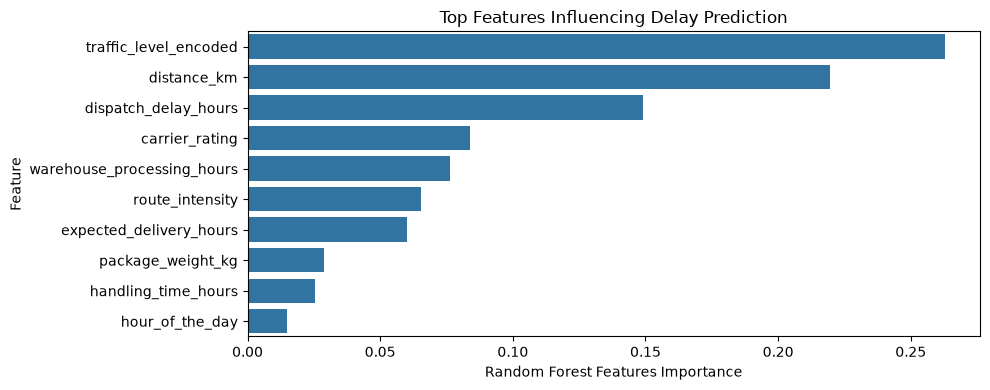

In [252]:
plt.figure(figsize=(10,4))

sns.barplot(
  data=feature_importances.head(10),
  x='Importance',
  y='Feature'
)

plt.title(
    'Top Features Influencing Delay Prediction'
)
plt.xlabel(
    'Random Forest Features Importance'
)

plt.ylabel(
    'Feature'
)

plt.tight_layout()

plt.savefig(
    r'D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks7\random_forest_feature_importance.png',bbox_inches ='tight'
)

plt.show()

# K-Means Cluster visualization

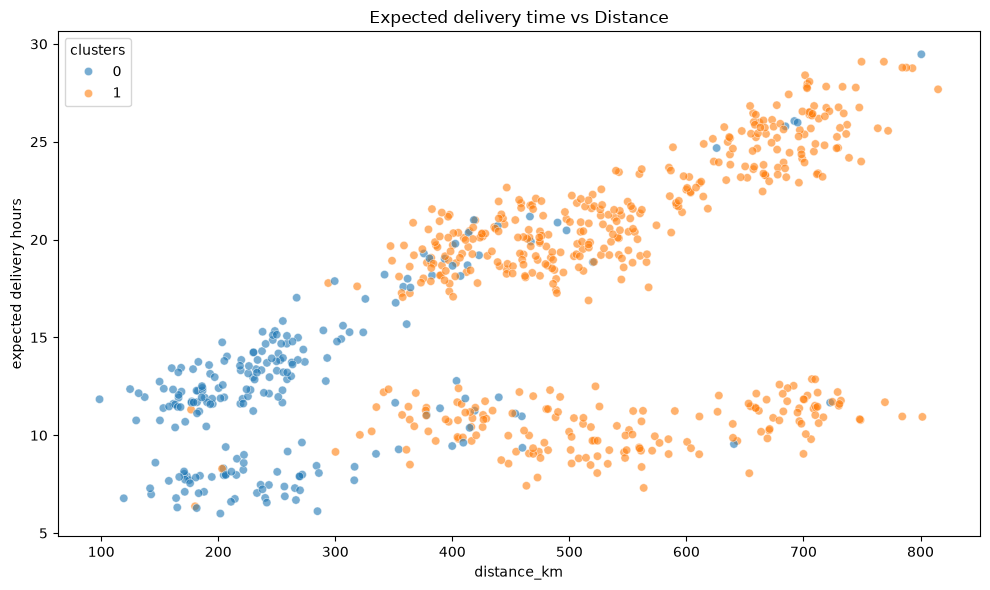

In [253]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data= shipment_data_df_copy,
    x='distance_km',
    y='expected_delivery_hours',
    hue='delay_required',
    alpha=0.6
)

plt.title('Expected delivery time vs Distance')
plt.xlabel("distance_km")
plt.ylabel('expected delivery hours')
plt.legend(title='clusters')

plt.tight_layout()
plt.savefig(r"D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks7\distance_vs_expectedDeliveryHours.png",bbox_inches='tight')

plt.show()

# Task 8 Validation, Testing and Operational Recommendation

In [254]:
sample_X = X_test.head(5)
sample_Y = Y_test.head(5)

sample_predictions = rf_cls.predict(sample_X)

validation_sample = pd.DataFrame({

    'Actual': sample_Y.values,
    'Predicted': sample_predictions
}
)

validation_sample

,Actual,Predicted
0,0,0
1,1,1
2,1,1
3,1,1
4,0,0


In [ ]:
target = 'delivery_delay_hours'

candidate_features = [
    'distance_km',
    'package_weight_kg',
    'carrier_rating',
    'expected_delivery_hours',
    'traffic_level_encoded',
    'day_of_the_week',
    'hour_of_the_day',
    'route_intensity'
]

x_reg = shipment_data_df_copy[candidate_features]
y_reg = shipment_data_df_copy[target]
print(x_reg)

Index(['distance_km', 'package_weight_kg', 'carrier_rating',
       'expected_delivery_hours', 'traffic_level_encoded', 'day_of_the_week',
       'hour_of_the_day', 'route_intensity'],
      dtype='str')


In [267]:
#chronological split

split_index = int(len(x)*0.8)

X_train_reg = x_reg[:split_index]
X_test_reg = x_reg[split_index:]
Y_train_reg = y_reg[:split_index]
Y_test_reg = y_reg[split_index:]

In [279]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_reg_scaled = scaler.fit_transform(X_train_reg)
X_test_reg_scaled = scaler.transform(X_test_reg)

from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_reg_scaled,Y_train_reg)

lr_pred = lr.predict(X_train_reg_scaled)
lr_pred.shape


(576,)

In [261]:
sample_X = X_test_reg.head(5)
sample_X_scaled = scaler.transform(sample_X)


sample_predictions_reg = lr.predict(sample_X_scaled)

validation_regression = pd.DataFrame({

    'Actual_Delay_Hours': Y_test_reg.head(5).values,
    'Predicted_Delay_Hours': sample_predictions_reg
}
)

validation_regression.round(2)

,Actual_Delay_Hours,Predicted_Delay_Hours
0,0.00,2.36
1,8.43,6.22
2,5.04,6.32
3,5.08,6.14
4,1.68,1.84


A small held-out sample from the chronological evaluation period was passed through the fitted preprocessing and predictions pipeline.

Both regression and classification pipelines successfully generated predictions without refitting preprocessing without refitting preprocessing components on evaluation data

In [ ]:
print("Regression training missing values:",X_train_reg.isnull().sum().sum())
print("Regression test missing values:",X_test_reg.isnull().sum().sum())
print("Classification training missing values:",X_train.isnull().sum().sum())
print("Classification test missing values:",X_test.isnull().sum().sum())
print("Clustering missing values:", cluster_x.)


Regression training missing values: 0
Regression test missing values: 0
Classification training missing values: 0
Classification test missing values: 0
Clustering missing values: [[-1.15619356 -0.65946548  1.00506736 ... -1.50755672 -0.50921611
  -0.65465367]
 [ 0.77845283  1.38971172  0.38796054 ... -0.30151134 -0.50921611
  -0.21821789]
 [ 1.41464841 -0.13974663 -1.49966032 ...  0.90453403 -0.50921611
   0.21821789]
 ...
 [ 0.23573212 -0.3921815  -0.48324909 ... -0.30151134 -1.50822318
   1.52752523]
 [ 0.84586803  0.70665265 -1.35445872 ...  0.90453403 -1.00871964
  -1.52752523]
 [-0.18235545  0.15723558 -0.01134388 ...  0.90453403 -1.00871964
  -1.09108945]]


All predictor datasets were verified to contain no missing value before model fitting

In [272]:
#Verify Target and Post-Outcome Leakage

post_outcome_feilds = [
    'actual_delivery_hours',
    'delivery_delay_hours',
    'delay_required'
]

def check_leakage(feature_df,dataset_name):
   leaked_columns = [
      col for col in post_outcome_feilds if col in feature_df.columns
   ]

   if len(leaked_columns) == 0:
      print(
         f"{dataset_name}:PASS -"
         "No target/post-outcome fields found."
      )
   else:
      print(
         f"{dataset_name}: FAIL -"
         f"Found {leaked_columns}"
      )

In [275]:
check_leakage(
    x_reg,
    "Regression predictors"
)

check_leakage(
    x,
    "Classification predictors"
)

check_leakage(
    cluster_x,
    "Unsupervised predictors"
)

Regression predictors:PASS -No target/post-outcome fields found.
Classification predictors:PASS -No target/post-outcome fields found.


AttributeError: 'numpy.ndarray' object has no attribute 'columns'

In [277]:
#Verify chronological Split

train_end_time = shipment_data_df_copy.loc[
    X_train.index,
    'shipment_timestamp'
].max()

test_start_time = shipment_data_df_copy.loc[
    X_test.index,
    'shipment_timestamp'
].min()

print("Training ends:", train_end_time)
print("Evaluation starts:",test_start_time)
print(
    "chronological split valid:",
    train_end_time <= test_start_time
)


Training ends: 2026-06-12 03:00:00
Evaluation starts: 2026-06-12 06:00:00
chronological split valid: True


The training period occurs entirely before the evalution period, confirming that future shipment records were not used to train models evaluated on earlier data 

In [281]:
from sklearn.metrics import mean_absolute_error,mean_squared_error

test_reg_predictions = lr.predict(X_test_reg_scaled)
test_mae = mean_absolute_error(
    Y_test_reg,
    test_reg_predictions
)

test_rsme = np.sqrt(
    mean_squared_error(
        Y_test_reg,
        test_reg_predictions
    )
)

print(f"Evaluation MAE:{test_mae:.2f} hours")
print(f"Evaluation RMSE: {test_rsme:.2f} hours")

Evaluation MAE:1.33 hours
Evaluation RMSE: 1.68 hours


In [282]:
from sklearn.metrics import confusion_matrix

test_cls_predictions = rf_cls.predict(X_test)

test_confusion_matrix = confusion_matrix(Y_test,test_cls_predictions)

print(test_confusion_matrix)


[[ 36   7]
 [  0 101]]


In [283]:
print("Evaluation records:",len(Y_test))
print("confusion matrix records:", test_confusion_matrix.sum())

Evaluation records: 144
confusion matrix records: 144


Regression metrics and the Random forest confusion matrix were regenerated using only the held-out chronological evaluation dataset

The number of observations represented in the confusion matrix matches the evaluation-set size , confirming that training predictions were not used for reported classification performance.

# Key Operational Findings 

- Linear Regression provides an initial estimate of delivery-delay duration, with an average error of ~1.33 hrs

- Regression errors increase for more extreme delay conditions, so delay-hour forecasts should be treated as estimates rather than exact arrival predictions.
- Random forest achived the strongest delay-risk classification performance, including 100% Recall on the evaluation dataset.
- Low-traffic shipments experience substantially lower delays than Medium and high traffic shipments 
- K-Means identified two broad shipment operating patterns: Lower-complexity shipments and higher-complexity long-haul shipments.
-Higher-complexity shipments combine longer routes heavier traffic and comparatively lower carrier ratings.


## Operational Recommendations

Routewise should prioritise planner intervention for shipments that:

1. Are classified as delay-risk by the Random Forest model.
2. Belong to the higher-complexity long-Haul shipment cluster.
3. Operate under Medium or High Traffic conditions.
4. Have long travel distances or comparatively lower-rated carriers.

The predicted delay duration from the regression model can then be used as supporting information to estimate the likely magnitude of the delay

## Limitations

- The models are trained on historical shipment patterns and may not capture new routes carriers or unexpected operational disruptions
- The regression model is less accurate for extreme delay conditions and should not be treated as an exact ETA system.
- The clustering solution has a relatively modest Silhouette Score (~0.28) indicating overalap between shipment operating patterns